In [1]:

!pip install -q transformers torch pillow gradio

In [2]:

from transformers import pipeline

print("Loading AI model...")

classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)

print("AI Model Loaded Successfully! 🚀")


Loading AI model...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

AI Model Loaded Successfully! 🚀


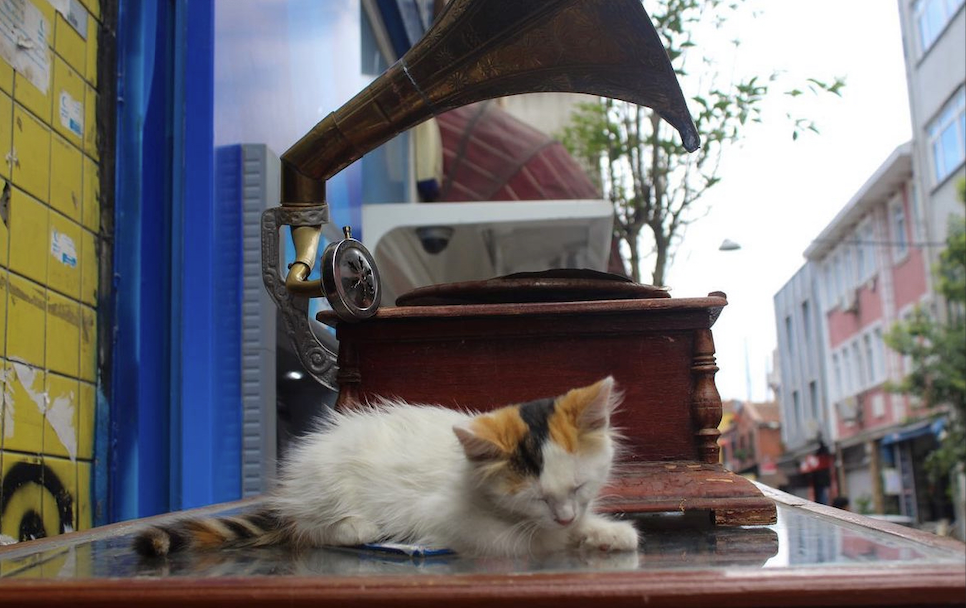


AI Predictions:
television, television system  -  2.35%
radio, wireless  -  2.22%
tape player  -  2.14%


In [3]:

from PIL import Image
import requests
from io import BytesIO

# Sample image
image_url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/cat.png"

# Download image
response = requests.get(image_url)
response.raise_for_status()

# Convert into RGB image
image = Image.open(
    BytesIO(response.content)
).convert("RGB")

# Display image
display(image)

# Ask AI to classify the image
results = classifier(image, top_k=3)

# Display predictions
print("\nAI Predictions:")

for result in results:
    print(
        result["label"],
        " - ",
        f'{result["score"]:.2%}'
    )


In [5]:

import gradio as gr

def predict_image(image):
    if image is None:
        return None

    predictions = classifier(
        image.convert("RGB"),
        top_k=3
    )

    return {
        item["label"]: float(item["score"])
        for item in predictions
    }

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="AI Image Classifier"
) as demo:

    gr.Markdown("""
    # 🤖 AI Image Classifier
    ### Upload an image and let Artificial Intelligence recognize it!

    Powered by Hugging Face Vision Transformer.
    """)

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Upload Your Image"
            )

            predict_btn = gr.Button(
                "🔍 Classify Image",
                variant="primary"
            )

        with gr.Column():
            output = gr.Label(
                num_top_classes=3,
                label="AI Predictions"
            )

    predict_btn.click(
        fn=predict_image,
        inputs=image_input,
        outputs=output
    )

    gr.Markdown("""
    ---
    **Technology:** Python | PyTorch | Hugging Face | Gradio
    """)

demo.launch(share=True)


/tmp/ipykernel_3144/3386450976.py:17: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f4150376aa946d6f95.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
